In [110]:
### Libararies - Joe
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, classification_report

### Part A - Implementation - Joe

In [111]:
### Random Seed - Joe
RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)

In [112]:
### Define constants - Joe
EPS = 10**-8
TAU = 10**-3
MAX_ITER = 10**4

In [113]:
### Kernel Functions where x and z are numpy arrays - Joe
def K1(x,z): # linear
    return x.T @ z
def K2(x,z): # feature space of K
    return np.square(K1(x,z)+1)

In [114]:
### 1, init - Joe
def InitSMO(X,y, KernelFunc, seed=RANDOM_SEED):
    m=len(y)
    np.random.seed(seed)

    # precompute gram mat
    K = np.zeros((m,m))
    for i in range(m):
        for j in range(m):
            K[i,j] = KernelFunc(X[i], X[j])

    # initialize alpha randomly
    U =np.random.uniform(0,1,m)
    alpha = np.zeros(m)
    alpha[y==1] = U[y==1] / np.sum(U[y==1]) # positive examples
    alpha[y==-1] = U[y==-1] / np.sum(U[y==-1]) # negative examples

    bias = 0
    return K,alpha,bias

In [115]:
### 2, evaluate decision func - Joe
def evalSMO(K,y,alpha,bias):
    return K @ (alpha * y) + bias
def evalSMO_Alt(X,y,alpha,bias):
    w = X.T @ (alpha*y)
    return X @ w + bias

In [116]:
### 3, compute errors and KKT quantities, and violations - Joe
def computeErrorSmo(K,y,alpha,bias):
    return evalSMO(K,y,alpha,bias) - y
def computeKKTSmo(K,y,alpha,bias):
    margin = y * evalSMO(K,y,alpha,bias)
    KKT = alpha * (margin-1)
    return KKT, margin
def computeKKTViolations(alpha,margin):
    return np.where(alpha>0,np.abs(margin-1), np.maximum(0,1-margin))

In [117]:
### 5, update ai2, clip it to feasible segment - Joe
def updateAlphaI2(alpha,y,i1,i2,e,k):
    ai1 = alpha[i1]
    ai2 = alpha[i2]

    # check bounds
    if y[i1] != y[i2]:
        L = max(0,ai2-ai1)
        H = np.inf
    else:
        L = 0
        H = ai1 +ai2

    # update values
    ai2_unc = ai2 + (y[i2] * e) / k
    ai2_new = np.clip(ai2_unc,L,H) #same as min(max(unc,L),H)

    return ai2_new

In [118]:
### 6, update ai1, preserving cond - Joe
def updateAlphaI1(alpha, y, i1, i2, ai2_new):
    ai1 = alpha[i1]
    ai2 = alpha[i2]

    # compute new and return
    return ai1 + y[i1]*y[i2]*(ai2-ai2_new)

In [119]:
### 8 - compute new bias - Joe
def computeBias(K,y,alpha,sV,b):
    if np.any(sV):
        b = np.mean(y[sV] - (K @ (alpha * y))[sV]) # [sV] is boolean that selects only support vectors
    return b

In [120]:
### pick pair loop - Joe
def pickPairLoop(K,y,alpha,bias, Error, KKT, margin,v, eps=EPS):
    updated = False

    # 4 - select i1 by next-worst violator
    i1List = np.argsort(-v)
    for i1 in i1List:
        # 4-(b) e(i)
        e = Error[i1] - Error

        # 4-(c) compute k for each i2
        ks = K[i1,i1] + np.diag(K) - (2*K[i1,:]) #K_ii is same as diag mat

        ## check greater than zero
        pos = ks >0
        pos[i1] = False # i \ne i1 condition

        ## edge case, none are valid
        if not np.any(pos):
            continue

        # 4 - select  i2 by next-best from the argmax
        absErrors = np.where(pos,np.abs(e), -np.inf) # assigns negative infinity to invalid candidates
        i2List = np.argsort(-absErrors)
        for i2 in i2List:
            # edgecheck - i2 not positive
            if not pos[i2]:
                continue

            k = ks[i2]

            # 5 - update alpha ai2
            ai2_new = updateAlphaI2(alpha,y,i1,i2,e[i2],k)

            # 6 - check if ai2 changed
            if abs(ai2_new - alpha[i2]) <= eps:
                continue

            # 6 - update alpha ai1
            ai1_new = updateAlphaI1(alpha,y,i1,i2,ai2_new)

            # apply updates
            alpha[i1] = ai1_new
            alpha[i2] = ai2_new

            updated = True
            break
        if updated:
            break
    return updated, alpha

In [121]:
### Implement SMO - Combining 1-6 with parts 7-10 in training loop - Joe
def smo(X,y,kernel, eps=10**-8,tau=10**-3,T=10**4,seed=0):
    m=len(y)

    # 1 - init
    K,alpha,bias = InitSMO(X,y,kernel, seed=seed)

    # 9 - Monitor
    wObjectives = []
    numSVs = []
    numMiscs= []
    constraintErrors = []

    iter = 0
    for iter in range(T):
        # 2 - evaluate decision function
        f = evalSMO(K,y,alpha,bias)

        # 3 - compute errors, KKT, quantities, violations
        Error = computeErrorSmo(K,y,alpha,bias)
        KKT, margin = computeKKTSmo(K,y,alpha,bias)
        v = computeKKTViolations(alpha,margin)

        # stopping test after step 3
        if np.max(v) < tau:
            print("Converged, iteration number {}".format(iter))
            break

        # 4 - select pair in order of worst KKT violations
        updated,alpha = pickPairLoop(K,y,alpha,bias,Error,KKT, margin,v,eps=eps)

        if not updated:
            print("Could not update any pair, end on iteration number {}".format(iter))
            break
        
        # 7 - Clean up
        alpha[alpha < eps] = 0

        # 8 - Recompute bias
        supportVectors = alpha > 0
        bias = computeBias(K,y,alpha,supportVectors,bias)

        # 9 - monitor

        ## objective function
        wObjective = np.sum(alpha) - 0.5 * ((alpha * y) @ K @ (alpha * y))

        ## number of support vectors
        numSV = np.sum(supportVectors)

        ## number of misclassified examples
        f = evalSMO(K,y,alpha,bias)
        miscs = np.sum(np.sign(f) != y)

        ## sum of constraint violations
        constraintError = np.sum(y*alpha)

        ## append to lists
        wObjectives.append(wObjective)
        numSVs.append(numSV)
        numMiscs.append(miscs)
        constraintErrors.append(constraintError)
        
    ## make into dict
    monitor = {
        "wObjectives": wObjectives,
        "numSVs": numSVs,
        "numMiscs": numMiscs,
        "constraintErrors": constraintErrors,
        "iters": iter
    }

    return alpha, bias, monitor


In [122]:
### sanity check with toy data - Joe
toyData = open("SMO_Data.txt", "r").readlines()
toyDf = pd.DataFrame([line.strip().split() for line in toyData], columns=["x1","x2","y"]).astype(int)

# split into train and test
toyXtr,toyXte,toyYtr,toyYte = train_test_split(toyDf[["x1","x2"]].values, toyDf["y"].values, test_size=0.5, random_state=RANDOM_SEED)

# onehot encode labels to -1 and 1
toyYtr = np.where(toyYtr == 0, -1, 1)
toyYte = np.where(toyYte == 0, -1, 1)

# train smo on toy data
alpha, bias, monitor = smo(
    toyXtr, toyYtr,
    kernel=K1, eps=EPS, tau=TAU,
    T=MAX_ITER, seed=RANDOM_SEED
)

K_test = toyXte @ toyXtr.T

vals = evalSMO(K_test, toyYtr, alpha, bias)
toyYpred = np.sign(vals)

print(confusion_matrix(toyYte, toyYpred))
print(accuracy_score(toyYte, toyYpred))

Converged, iteration number 165
[[ 49   0]
 [  0 101]]
1.0


### Part B - Experiements - Joe

In [123]:
### Helper Plot Decision Boundary function - Joe
#https://www.geeksforgeeks.org/machine-learning/visualizing-support-vector-machines-svm-using-python/
#https://scikit-learn.org/stable/auto_examples/svm/plot_linearsvc_support_vectors.html
#https://medium.com/@isurusandaruwan3840/visualizing-support-vector-machines-svm-using-python-b05d666b197f
def plotSMO(Xtr,ytr,Kernel, alpha, bias, plt_title, EPS=EPS):
    fig,ax = plt.subplots()

    # create a grid/mesh for decision boundaries
    x1 = np.linspace(Xtr[:, 0].min()-1, Xtr[:, 0].max()+1, 200)
    x2 = np.linspace(Xtr[:, 1].min()-1, Xtr[:, 1].max()+1, 200)
    xx, yy = np.meshgrid(x1, x2)
    grid = np.c_[xx.ravel(), yy.ravel()]

    # plot decision boundary
    if Kernel==K1:
        k = grid @ Xtr.T 
    else:
        k = (grid @ Xtr.T +1)**2
    f = evalSMO(k,ytr,alpha, bias)
    f = f.reshape(xx.shape)


    # plot data
    ax.scatter(Xtr[:, 0], Xtr[:, 1],c=ytr, cmap="bwr")
    # plot decision boundary
    ax.contour(
        xx, yy, f,
        levels=[-1, 0, 1],
        colors=["black", "red", "black"],
        linestyles=["--", "-", "--"],
    )    
    # plot and circle support vectors
    sv = alpha > EPS
    ax.scatter(
        Xtr[sv, 0], Xtr[sv, 1],
        s=150,
        facecolors="none",
        edgecolors="green",
        label="Support Vectors"
    )
    ax.legend()
    plt.title(plt_title)
    plt.show()


In [131]:
### Helper Plot W(a) and Miscs vs iteration - Joe
def plotW_Misc_vIteration(wObjs, numMiscs, iters, plt_title):
    iters = np.arange(1, iters + 1)
    plt.plot(iters, wObjs, label="W(a)")
    plt.plot(iters,numMiscs, label="Misclassifications")
    plt.xlabel("Iteration")
    plt.ylabel("Value")
    plt.title(plt_title)
    plt.legend()
    plt.show()

Converged, iteration number 71


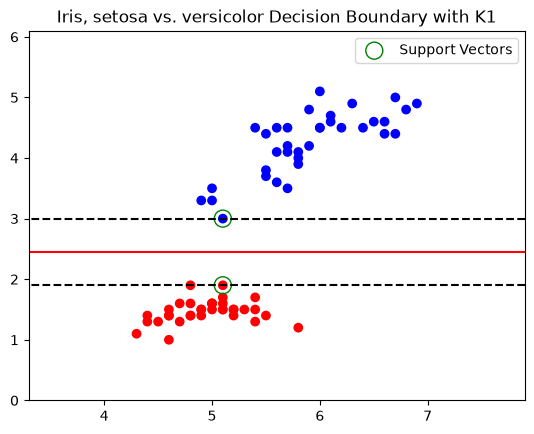

Evaluation on Train Data
[[35  0]
 [ 0 35]]
1.0
Evaluation on Test Data
[[15  0]
 [ 0 15]]
1.0
W2Norm : 3.3058
SumAlpha: 3.3058


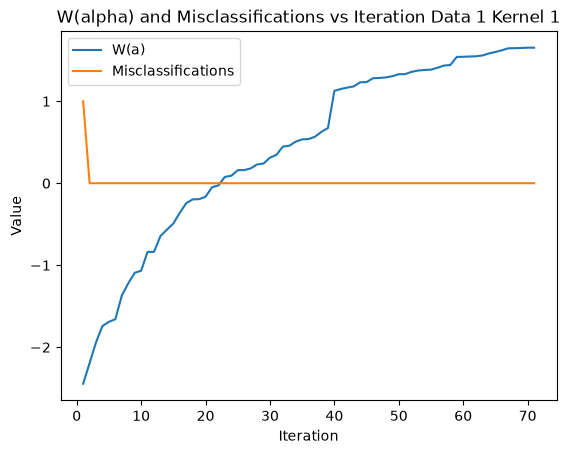

In [ ]:
### Data set 1 - Kernel 1 - Iris,Setosa vs Versicolor - Joe
trainDF = pd.read_csv("SMO_data/iris_setosa_versicolor_train.csv")
testDF = pd.read_csv("SMO_data/iris_setosa_versicolor_test.csv")

# split into train and test
Xtr = trainDF[["sepal_length","petal_length"]].values
Xte = testDF[["sepal_length","petal_length"]].values

# train smo on iris data - kernel 1
alpha, bias, d1k1monitor = smo(
    Xtr, trainDF["y"].values,
    kernel=K1, eps=EPS, tau=TAU,
    T=MAX_ITER, seed=RANDOM_SEED
)

# grab train and test predictions
K1_train = Xtr @ Xtr.T
K1_test = Xte @ Xtr.T

K1_vals = evalSMO(K1_train, trainDF["y"].values, alpha, bias)
K1_ytr_preds = np.sign(K1_vals)

K1_vals = evalSMO(K1_test, trainDF["y"].values, alpha, bias)
K1_yte_preds = np.sign(K1_vals)

# 1- plot decision boundary
plotSMO(Xtr,trainDF["y"].values,K1,alpha,bias, "Iris, setosa vs. versicolor Decision Boundary with K1", EPS=EPS)

# 2 - Output confusion matrix and acc
print("Evaluation on Train Data")
print(confusion_matrix(trainDF["y"].values, K1_ytr_preds))
print(accuracy_score(trainDF["y"].values, K1_ytr_preds))

print("Evaluation on Test Data")
print(confusion_matrix(testDF["y"].values, K1_yte_preds))
print(accuracy_score(testDF["y"].values, K1_yte_preds))

# 3 - check ||w||2 norm agrees with sum alpha
w2Norm = np.sum((alpha * trainDF["y"].values) @ K1_train @ (alpha * trainDF["y"].values))
sumAlpha = np.sum(alpha)
print("W2Norm : {:.4f}".format(w2Norm))
print("SumAlpha: {:.4f}".format(sumAlpha))

# 4 - plot w(a) and the number of miscs vs iterations
plotW_Misc_vIteration(d1k1monitor["wObjectives"], d1k1monitor["numMiscs"], d1k1monitor["iters"]
                      ,"W(alpha) and Misclassifications vs Iteration Data 1 Kernel 1")

Converged, iteration number 71


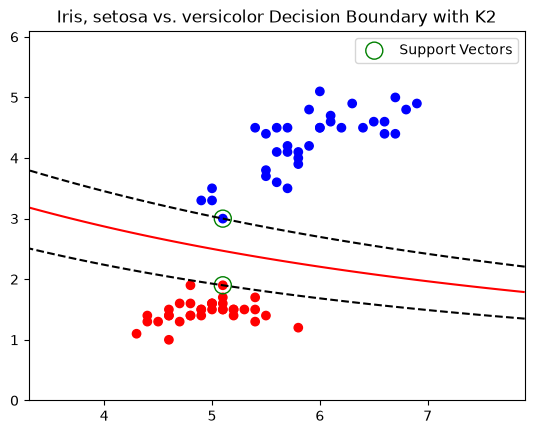

Evaluation on Train Data
[[35  0]
 [ 0 35]]
1.0
Evaluation on Test Data
[[15  0]
 [ 0 15]]
1.0
W2Norm : 0.0424
SumAlpha: 0.0424


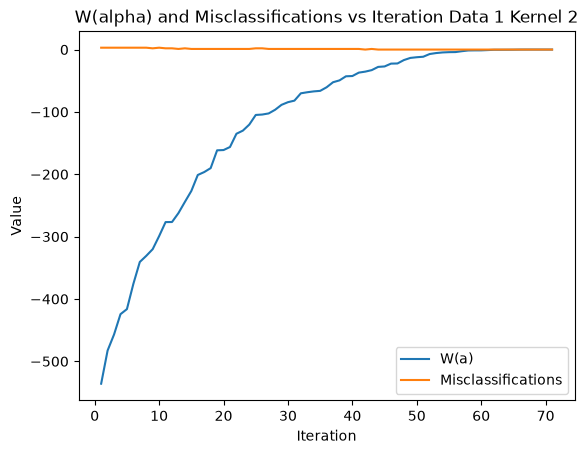

In [ ]:
### Data set 1 - Kernel 2 - Iris,Setosa vs Versicolor - Joe
trainDF = pd.read_csv("SMO_data/iris_setosa_versicolor_train.csv")
testDF = pd.read_csv("SMO_data/iris_setosa_versicolor_test.csv")

# split into train and test
Xtr = trainDF[["sepal_length","petal_length"]].values
Xte = testDF[["sepal_length","petal_length"]].values

# train smo on iris data - kernel 2
alpha, bias, d1k1monitor = smo(
    Xtr, trainDF["y"].values,
    kernel=K2, eps=EPS, tau=TAU,
    T=MAX_ITER, seed=RANDOM_SEED
)

# grab train and test predictions
K2_train =(Xtr @ Xtr.T + 1)**2
K2_test = (Xte @ Xtr.T + 1)**2

K2_vals = evalSMO(K2_train, trainDF["y"].values, alpha, bias)
K2_ytr_preds = np.sign(K2_vals)

K2_vals = evalSMO(K2_test, trainDF["y"].values, alpha, bias)
K2_yte_preds = np.sign(K2_vals)

# 1 - plot decision boundary
plotSMO(Xtr,trainDF["y"].values,K2,alpha,bias, "Iris, setosa vs. versicolor Decision Boundary with K2", EPS=EPS)

# 2 - Output confusion matrix and acc
print("Evaluation on Train Data")
print(confusion_matrix(trainDF["y"].values, K2_ytr_preds))
print(accuracy_score(trainDF["y"].values, K2_ytr_preds))

print("Evaluation on Test Data")
print(confusion_matrix(testDF["y"].values, K2_yte_preds))
print(accuracy_score(testDF["y"].values, K2_yte_preds))

# 3 - check ||w||2 norm agrees with sum alpha
w2Norm = np.sum((alpha * trainDF["y"].values) @ K2_train @ (alpha * trainDF["y"].values))
sumAlpha = np.sum(alpha)
print("W2Norm : {:.4f}".format(w2Norm))
print("SumAlpha: {:.4f}".format(sumAlpha))

# 4 - plot w(a) and the number of miscs vs iterations
plotW_Misc_vIteration(d1k1monitor["wObjectives"], d1k1monitor["numMiscs"], d1k1monitor["iters"]
                      ,"W(alpha) and Misclassifications vs Iteration Data 1 Kernel 2")